# Stockout-aware forecasting
### DATA 245 · Ridge Regression classroom demo

## 1. Project overview and research question

**Does adding historical stockout information improve next-day recorded-sales forecasts?**

We use FreshRetailNet-50K to forecast normalized recorded `sale_amount` for a
store–product series. A stockout can censor observed sales; the target is still
**recorded sales**, not unobserved demand.

This notebook demonstrates the saved **V2 stockout-aware Ridge, alpha = 100**.
Its artifact was reproduced using the approved final training procedure; it is
not the unavailable original fitted object. The source final experiment is
`final-1000-attested-20261124T094349Z`.

**Live demo:** select **DATA245 Ridge Demo (Python 3.12)**, then **Restart Kernel
and Run All Cells**. The authentic embedded test example works without the
external data bundle. If the approved bundle is found, the notebook also checks
all 15,000 test rows and draws their diagnostic plots. No cell trains a model.


## 2. Imports, verified environment and artifact paths

Paths are discovered from the working directory, so this notebook runs from
either the repository root or `submission_local/demo`. We import the existing
entry point as a Python module; its CLI is not executed.


In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import importlib.util
import inspect
import os
import platform
import sys

sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Code, Markdown, display
get_ipython().run_line_magic('matplotlib', 'inline')

roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
REPO_ROOT = next((p for p in roots
                  if (p / 'submission_local/demo/ml_pipeline.py').is_file()
                  and (p / 'src/features_DELTA/v2.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Open this notebook from the repository root or its demo directory.')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DEMO_DIR = REPO_ROOT / 'submission_local/demo'
SCRIPT_PATH = DEMO_DIR / 'ml_pipeline.py'
MODEL_PATH = DEMO_DIR / 'stockout_aware_ridge.joblib'
spec = importlib.util.spec_from_file_location('data245_demo', SCRIPT_PATH)
demo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(demo)

def file_sha256(path):
    with Path(path).open('rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()

EXPECTED_HASHES = {
    SCRIPT_PATH: '2398245feafd8ddc7fc879e8c458cb3405ca155e56a7467960cceb7d3e47454a',
    MODEL_PATH: '50f6f3c8e7dbf6ce6c97508bf7fb0b69ba0ecaee1234ded10cf497bc0d84407c',
}
assert all(file_sha256(p) == digest for p, digest in EXPECTED_HASHES.items())
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
print(f'Interpreter: {sys.executable}')
print(f'Repository: {REPO_ROOT}')
print('Original script and model SHA-256 checks: PASS')


Interpreter: C:\Users\timho\AppData\Local\Temp\data245-ridge-demo-py312\Scripts\python.exe
Repository: C:\Projects\data245-group3
Original script and model SHA-256 checks: PASS


In [2]:
EXPECTED_CORE = {'python': '3.12.10', 'numpy': '2.4.3', 'pandas': '3.0.1',
                 'scikit-learn': '1.9.0', 'joblib': '1.6.0', 'scipy': '1.18.1'}
runtime_versions = {'python': platform.python_version(), **{
    name: version(name) for name in EXPECTED_CORE if name != 'python'}}
assert runtime_versions == EXPECTED_CORE, 'Select the registered DATA245 Ridge Demo kernel.'
environment_table = pd.DataFrame([
    {'Package': name, 'Version': current, 'Purpose': 'Verified model environment'}
    for name, current in runtime_versions.items()
] + [
    {'Package': name, 'Version': version(name), 'Purpose': 'Notebook / visualization'}
    for name in ['jupyterlab', 'ipykernel', 'nbclient', 'nbformat', 'matplotlib']
])
display(environment_table.style.hide(axis='index').set_caption('Active kernel environment'))


Package,Version,Purpose
python,3.12.10,Verified model environment
numpy,2.4.3,Verified model environment
pandas,3.0.1,Verified model environment
scikit-learn,1.9.0,Verified model environment
joblib,1.6.0,Verified model environment
scipy,1.18.1,Verified model environment
jupyterlab,4.6.6,Notebook / visualization
ipykernel,7.4.0,Notebook / visualization
nbclient,0.11.0,Notebook / visualization
nbformat,5.11.1,Notebook / visualization


**Optional data configuration.** Leave `DATA_BUNDLE_PATH` unset for automatic
discovery. A `Path` or the `DATA245_DEMO_BUNDLE` environment variable can point
to another copy. Missing data does not prevent the embedded example from running;
an existing bundle with the wrong identity fails validation rather than being substituted.


In [3]:
DATA_BUNDLE_PATH = os.environ.get('DATA245_DEMO_BUNDLE')  # Optional Path/string; None = discover.
RUN_COMPLETE_TEST_EVALUATION = True                     # False = embedded example only.

bundle_candidates = [
    REPO_ROOT / 'data/processed/feature_bundles/v2-final-1000-r2',
    Path.home() / 'Downloads/data-20261124T182319Z-1-001/data/processed/feature_bundles/v2-final-1000-r2',
]
if DATA_BUNDLE_PATH is not None:
    configured_path = Path(os.path.expandvars(str(DATA_BUNDLE_PATH))).expanduser()
    bundle_path = configured_path if configured_path.is_dir() else None
else:
    bundle_path = next((p for p in bundle_candidates if p.is_dir()), None)
print('Optional bundle:', bundle_path if bundle_path else 'unavailable; embedded demo remains ready')


Optional bundle: C:\Users\timho\Downloads\data-20261124T182319Z-1-001\data\processed\feature_bundles\v2-final-1000-r2


## 3. Dataset overview and chronological split

The approved final cohort has **1,000 complete store–product series**, selected
by deterministic SHA-256 key ranking with seed **245**, without outcome-derived
strata. Each series spans March 28–June 25, 2024. The first **14 days** supply
history, leaving **76,000 eligible targets**, including target dates with stockouts.

The split follows the calendar; there is no shuffle. Preprocessing and Ridge
were fitted on training observations only. Development validation selected alpha;
the final run retained that frozen choice without validation refitting or test tuning.


In [4]:
from src.data_preprocessing_DELTA.v2 import CALENDAR

split_table = pd.DataFrame([
    {'Split': 'train', 'Target start': CALENDAR[14].date(), 'Target end': CALENDAR[59].date(),
     'Rows': demo.COUNTS['train'], 'Use': 'Fit scaler and Ridge only'},
    {'Split': 'validation', 'Target start': CALENDAR[60].date(), 'Target end': CALENDAR[74].date(),
     'Rows': demo.COUNTS['validation'], 'Use': 'Frozen choice; no final refit'},
    {'Split': 'test', 'Target start': CALENDAR[75].date(), 'Target end': CALENDAR[89].date(),
     'Rows': demo.COUNTS['test'], 'Use': 'Inference / descriptive evaluation'},
])
display(split_table.style.hide(axis='index').format({'Rows': '{:,}'}))


Split,Target start,Target end,Rows,Use
train,2024-04-11,2024-05-26,"46,000",Fit scaler and Ridge only
validation,2024-05-27,2024-06-10,"15,000",Frozen choice; no final refit
test,2024-06-11,2024-06-25,"15,000",Inference / descriptive evaluation


## 4. Feature engineering: sales lags and rolling averages

DELTA is the single feature producer. Sales lags use **1, 2, 3, 7 and 14 prior
days**; rolling means use the previous **7 and 14 days**. Calendar predictors
are weekday and weekend. Five historical stockout summaries extend this condition.

The executable cell below displays an excerpt from the **actual imported DELTA
function**. It does not reimplement or regenerate features. For inference, we
reuse either the artifact's authentic row or DELTA's validated serialized bundle.


In [5]:
from src.features_DELTA import v2 as delta_features
from src.features_DELTA.bundle import spec as delta_feature_spec

feature_specification = delta_feature_spec()
feature_source = inspect.getsource(delta_features.build_features)
start = feature_source.index('    groups =')
end = feature_source.index('    out["weekday"]')
print('Source: src/features_DELTA/v2.py :: build_features')
display(Code(feature_source[start:end], language='python'))


Source: src/features_DELTA/v2.py :: build_features


groups = frame.groupby(SERIES, sort=False)
    out = frame[KEY].copy()
    for lag in (1, 2, 3, 7, 14):
        out[f"sales_lag_{lag}"] = groups.sale_amount.shift(lag)
    for window in (7, 14):
        out[f"sales_mean_{window}"] = groups.sale_amount.transform(lambda s: s.shift(1).rolling(window).mean())
        out[f"stockout_hours_mean_{window}"] = groups.stock_hour6_22_cnt.transform(lambda s: s.shift(1).rolling(window).mean())
        out[f"stockout_day_fraction_{window}"] = groups.stock_hour6_22_cnt.transform(lambda s: s.gt(0).shift(1).rolling(window).mean())
    out["stockout_hours_lag_1"] = groups.stock_hour6_22_cnt.shift(1)

## 5. Leakage prevention: grouped shift(1) before rolling

For target date **t**, each rolling window reads **t−w through t−1**. DELTA sorts
by `(store_id, product_id, dt)`, groups by store–product series, and applies
`shift(1)` **before** `rolling(w)`. This excludes the target day's sales and
stockout status and prevents history from crossing series boundaries.

Store/product IDs are keys. Target-day stockout metadata is retrospective
evaluation information and never enters the predictor allowlist. Earlier
observed validation/test days may supply history for later one-day forecasts;
scaler and model parameters remain fixed. Calendar predictors are known at forecast time.


In [6]:
from src.models.linear_regression_DEVGRU.core import FORBIDDEN_PREDICTORS

assert demo.FEATURES == delta_features.COMMON + delta_features.EXTRA
assert not set(demo.FEATURES).intersection(FORBIDDEN_PREDICTORS)
timing_features = ['sales_lag_14', 'sales_mean_7', 'stockout_hours_mean_14',
                   'stockout_day_fraction_7']
display(pd.DataFrame([
    {'Feature': name, 'Allowed history': feature_specification['definitions'][name]['timing']}
    for name in timing_features
]).style.hide(axis='index'))
print('Approved allowlist and past-only timing checks: PASS')


Feature,Allowed history
sales_lag_14,t-14
sales_mean_7,t-7 through t-1 inclusive
stockout_hours_mean_14,t-14 through t-1 inclusive
stockout_day_fraction_7,t-7 through t-1 inclusive


Approved allowlist and past-only timing checks: PASS


## 6. Sales-only 9 features vs stockout-aware 14 features

Both experimental conditions share identical keys, targets and split labels.
The stockout-aware condition adds five predictors to the same nine common
features. This notebook loads only the saved stockout-aware model; the feature
comparison below documents the design rather than fitting a second model.


In [7]:
feature_order = pd.DataFrame([
    {'Order': i, 'Feature': name,
     'Condition': 'Both (sales-only + aware)' if name in delta_features.COMMON else 'Aware addition',
     'Timing': feature_specification['definitions'][name]['timing']}
    for i, name in enumerate(demo.FEATURES, start=1)
])
assert len(delta_features.COMMON) == 9 and len(demo.FEATURES) == 14
display(feature_order.style.hide(axis='index').set_caption('Exact model input order'))


Order,Feature,Condition,Timing
1,sales_lag_1,Both (sales-only + aware),t-1
2,sales_lag_2,Both (sales-only + aware),t-2
3,sales_lag_3,Both (sales-only + aware),t-3
4,sales_lag_7,Both (sales-only + aware),t-7
5,sales_lag_14,Both (sales-only + aware),t-14
6,sales_mean_7,Both (sales-only + aware),t-7 through t-1 inclusive
7,sales_mean_14,Both (sales-only + aware),t-14 through t-1 inclusive
8,weekday,Both (sales-only + aware),known target calendar date
9,is_weekend,Both (sales-only + aware),known target calendar date
10,stockout_hours_lag_1,Aware addition,t-1


## 7. Load the saved Ridge model and fitted scaler

The trusted joblib payload is a **dictionary**, containing a fitted
`StandardScaler → Ridge` pipeline, feature names, configuration, provenance,
library versions and an authentic test row. We call the original script's
`load_model()` validator.

The pipeline already includes scaling. Pass the **unscaled approved features**
directly to `pipeline.predict()`; do not call `scaler.transform()` first.
Ridge's numerical state came from the unchanged DEVGRU augmented least-squares
solver, not a different sklearn training procedure.


In [8]:
artifact = demo.load_model(MODEL_PATH)
pipeline = artifact['pipeline']
scaler = pipeline.named_steps['scaler']
ridge = pipeline.named_steps['ridge']
assert artifact['feature_names'] == demo.FEATURES
assert int(scaler.n_samples_seen_) == 46000
assert ridge.alpha == 100.0
assert all(runtime_versions[name] == artifact['library_versions'][name]
           for name in runtime_versions)
provenance = artifact['training_provenance']
model_details = pd.DataFrame([
    {'Property': 'Payload', 'Value': 'Dictionary with fitted Pipeline and provenance'},
    {'Property': 'Ridge alpha / feature count', 'Value': f'{ridge.alpha:g} / {len(demo.FEATURES)}'},
    {'Property': 'Scaler fit observations', 'Value': f'{int(scaler.n_samples_seen_):,} training rows only'},
    {'Property': 'Artifact purpose', 'Value': artifact['purpose']},
    {'Property': 'Training provenance', 'Value': provenance['status']},
    {'Property': 'Source final experiment', 'Value': provenance['source_final_run_id']},
])
display(model_details.style.hide(axis='index'))


Property,Value
Payload,Dictionary with fitted Pipeline and provenance
Ridge alpha / feature count,100 / 14
Scaler fit observations,"46,000 training rows only"
Artifact purpose,submission_demo_reproduction
Training provenance,REPRODUCED_TRAINING; original fitted artifact unavailable
Source final experiment,final-1000-attested-20261124T094349Z


## 8. Predict the authentic embedded example

The artifact contains one real test observation for **store 0, product 122,
June 11, 2024**. Its 14 feature values were preserved from the approved bundle.
This is a single next-day example, not a complete test evaluation.


In [9]:
example = artifact['demo_observation']
example_X = pd.DataFrame([[example[name] for name in demo.FEATURES]], columns=demo.FEATURES)
prediction = float(pipeline.predict(example_X)[0])  # Scaling happens exactly once inside Pipeline.
actual = float(example['actual'])
absolute_error = abs(prediction - actual)
assert example['split'] == 'test'
np.testing.assert_allclose(prediction, 1.241823058952, rtol=0, atol=1e-12)
np.testing.assert_allclose(actual, 0.9, rtol=0, atol=1e-15)
np.testing.assert_allclose(absolute_error, 0.341823058952, rtol=0, atol=1e-12)
print(f"Test observation: store={example['store_id']}, product={example['product_id']}, date={example['dt']}")
print('Embedded example prediction check: PASS')


Test observation: store=0, product=122, date=2024-06-11
Embedded example prediction check: PASS


## 9. Actual, predicted and absolute error

All values below use the dataset's normalized recorded-sales scale. The model
overpredicts this example; one observation does not establish model-wide performance.


In [10]:
example_result = pd.DataFrame([{
    'Actual recorded sales': actual,
    'Ridge prediction': prediction,
    'Absolute prediction error': absolute_error,
}])
display(example_result.style.hide(axis='index').format('{:.12f}')
        .set_caption(f"Authentic test example · {example['dt']} · store {example['store_id']} / product {example['product_id']}"))


Actual recorded sales,Ridge prediction,Absolute prediction error
0.900000000000,1.241823058952,0.341823058952


## 10. Optional complete test-set evaluation

If available, `load_inputs()` verifies the exact bundle-manifest hash, every
artifact hash, schemas, 1,000-series coverage, feature order and chronological
split counts. `verify()` reuses the saved pipeline; it performs no fitting or tuning.

The primary metric is **MAE = mean(|prediction − actual|)** over all **15,000
test rows**, including stockout targets. We compare with the saved final
stockout-aware Ridge score, **0.37719137988468526**. The original full prediction
CSV is checked by its recorded hash if present; aggregate MAE agreement alone
does not prove row-by-row identity when that original CSV is missing.


In [11]:
EXPECTED_FINAL_MAE = 0.37719137988468526
joined = None
test_results = None
verification = None
if not RUN_COMPLETE_TEST_EVALUATION:
    print('Complete test evaluation disabled by configuration. Embedded demo passed.')
elif bundle_path is None:
    print('SKIPPED complete test evaluation: approved external feature bundle not found.')
    print('The embedded example above remains fully executable; no substitute data are generated.')
else:
    joined, bundle_manifest = demo.load_inputs(bundle_path)
    reference_path = (REPO_ROOT / 'results/final_evaluation/v2' / demo.RUN_ID / 'predictions.csv')
    reference = reference_path if reference_path.is_file() else None
    verification = demo.verify(pipeline, joined, reference)
    test_mask = joined['split'].eq('test')
    test_results = joined.loc[test_mask, demo.KEY + ['actual']].copy()
    test_results['prediction'] = pipeline.predict(joined.loc[test_mask, demo.FEATURES])
    test_results['absolute_error'] = abs(test_results['prediction'] - test_results['actual'])
    assert len(test_results) == 15000
    np.testing.assert_allclose(verification['test_mae'], EXPECTED_FINAL_MAE, rtol=0, atol=1e-12)
    np.testing.assert_allclose(test_results['absolute_error'].mean(), verification['test_mae'],
                               rtol=0, atol=1e-15)
    embedded_match = test_results.loc[
        test_results.store_id.eq(example['store_id'])
        & test_results.product_id.eq(example['product_id']) & test_results.dt.eq(example['dt'])]
    assert len(embedded_match) == 1
    np.testing.assert_allclose(embedded_match.prediction.iloc[0], prediction, rtol=0, atol=1e-12)
    np.testing.assert_allclose(embedded_match.actual.iloc[0], actual, rtol=0, atol=1e-15)
    display(pd.DataFrame([{
        'Test rows': len(test_results), 'Recomputed MAE': verification['test_mae'],
        'Recorded final MAE': EXPECTED_FINAL_MAE,
        'MAE difference': verification['test_mae'] - EXPECTED_FINAL_MAE,
    }]).style.hide(axis='index').format({'Test rows': '{:,}', 'Recomputed MAE': '{:.15f}',
                                        'Recorded final MAE': '{:.15f}', 'MAE difference': '{:.3e}'}))
    print('Full test MAE agreement: PASS (absolute tolerance 1e-12)')
    print('Original prediction comparison:', verification['prediction_comparison']['status'])


Test rows,Recomputed MAE,Recorded final MAE,MAE difference
"15,000",0.377191379884685,0.377191379884685,0.000e+00


Full test MAE agreement: PASS (absolute tolerance 1e-12)
Original prediction comparison: UNVERIFIED: original final predictions.csv unavailable


## 11. Actual vs predicted results and MAE

The left panel uses **every test observation**. The diagonal represents exact
prediction. The right panel follows the same store–product series as the embedded
example across its 15 test dates, chosen by that fixed key rather than performance.
Plots are produced only from the verified bundle and saved model predictions.


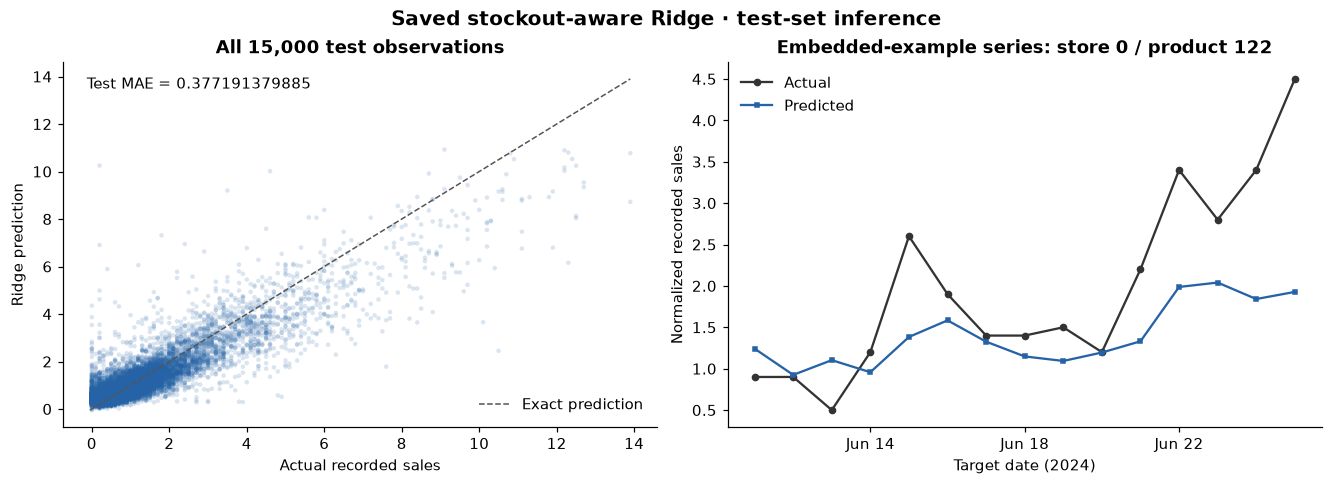

In [12]:
if test_results is None:
    print('SKIPPED test plots: no complete test evaluation was performed. No synthetic plot is substituted.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
    ax = axes[0]
    ax.scatter(test_results.actual, test_results.prediction, s=9, alpha=0.16,
               color='#2563a6', edgecolors='none', rasterized=True)
    low = float(min(test_results.actual.min(), test_results.prediction.min()))
    high = float(max(test_results.actual.max(), test_results.prediction.max()))
    ax.plot([low, high], [low, high], linestyle='--', color='#555555', linewidth=1, label='Exact prediction')
    ax.set(xlabel='Actual recorded sales', ylabel='Ridge prediction', title='All 15,000 test observations')
    ax.text(0.04, 0.96, f"Test MAE = {verification['test_mae']:.12f}",
            transform=ax.transAxes, va='top', fontsize=10)
    ax.legend(loc='lower right', frameon=False)

    series = test_results.loc[test_results.store_id.eq(example['store_id'])
                              & test_results.product_id.eq(example['product_id'])].sort_values('dt')
    assert len(series) == 15
    dates = pd.to_datetime(series['dt'])
    ax = axes[1]
    ax.plot(dates, series.actual, marker='o', markersize=4, color='#333333', label='Actual')
    ax.plot(dates, series.prediction, marker='s', markersize=3, color='#2563a6', label='Predicted')
    ax.set(xlabel='Target date (2024)', ylabel='Normalized recorded sales',
           title=f"Embedded-example series: store {example['store_id']} / product {example['product_id']}")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.legend(frameon=False)
    fig.suptitle('Saved stockout-aware Ridge · test-set inference', fontsize=13, fontweight='bold')
    plt.show()


## 12. Final results, limitations and conclusion

- **Verified reproduction:** alpha = 100, 14 features in their original order,
  fitted training-only scaler, 46,000 fitted training rows. The embedded example
  predicts approximately **1.241823058952** against actual **0.9**.
- **Recorded final test MAE:** **0.37719137988468526**. The status cell below
  distinguishes a fresh full-bundle check from the artifact's previously saved
  verification when data are unavailable.
- **Evidence boundary:** matching aggregate MAE does not prove row-level identity
  to the original final-run predictions. The missing original fitted model was
  reproduced, not recovered. No retraining occurs in this notebook.
- **Scientific limits:** recorded sales are not latent demand; historical holdout
  exposure and retrospective 90-day completeness limit confirmatory interpretation.
  The sampled 1,000 series need not represent the population. Raw-export lineage,
  normalization coefficient and undocumented business-hour semantics remain limited.
- **Conclusion:** this notebook demonstrates the approved saved forecasting
  pipeline. A single example cannot establish an improvement over sales-only
  models, subgroup benefits, causal effects or sustainability outcomes.

Sources: [approved protocol](../../docs/experiment_protocol.md),
[DELTA handoff](../../docs/DELTA_DATA_HANDOFF.md),
[saved final execution](../../docs/final_execution_evidence/final-1000-attested-20261124T094349Z/FINAL_VERIFIED_EXECUTION.md),
and [Jupyter setup / verification](README_JUPYTER.md).


In [13]:
assert all(file_sha256(p) == digest for p, digest in EXPECTED_HASHES.items())
status_rows = [
    {'Check': 'Authentic embedded example', 'Status': 'PASS'},
    {'Check': 'Original script and joblib bytes', 'Status': 'UNCHANGED (SHA-256 verified)'},
    {'Check': 'Training in this notebook', 'Status': 'NONE'},
    {'Check': 'Full test MAE', 'Status':
        f"PASS: {verification['test_mae']:.17g}" if verification is not None
        else f"SKIPPED: prior artifact verification = {artifact['verification']['test_mae']:.17g}"},
    {'Check': 'Original final prediction identity', 'Status':
        verification['prediction_comparison']['status'] if verification is not None
        else artifact['verification']['prediction_comparison']['status']},
]
display(pd.DataFrame(status_rows).style.hide(axis='index').set_caption('This execution: verification status'))
print('Ready for the classroom: saved-model inference completed without retraining.')


Check,Status
Authentic embedded example,PASS
Original script and joblib bytes,UNCHANGED (SHA-256 verified)
Training in this notebook,NONE
Full test MAE,PASS: 0.37719137988468526
Original final prediction identity,UNVERIFIED: original final predictions.csv unavailable


Ready for the classroom: saved-model inference completed without retraining.
